## Setup & Imports

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import xlrd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE  = 42
DATA_FILE     = 'cardiotocography_data_set.xls'
SHEET_NAME    = 'Raw Data'

FEATURE_GROUPS = {
    1: ['LB', 'ALTV', 'Min', 'Mean'],
    2: ['ASTV', 'MLTV', 'Max', 'Median'],
    3: ['MSTV', 'Width', 'Mode', 'Variance'],
}
FEATURE_GROUP = 1
FEATURES      = FEATURE_GROUPS[FEATURE_GROUP]

print(f"Feature Group {FEATURE_GROUP}: {FEATURES}")

## Question 1 : Data Loading & Label Engineering

Steps:
1. Load the Excel "Raw Data" worksheet into a Pandas DataFrame  
2. Combine NSP labels: NSP=1 → Normal (class 1), NSP∈{2,3} → Abnormal (class 0)


In [9]:
# Load with xlrd (required for legacy .xls binary format)

import os

wb      = xlrd.open_workbook(DATA_FILE)
ws      = wb.sheet_by_name(SHEET_NAME)
headers = [ws.cell_value(0, j) for j in range(ws.ncols)]
data    = [[ws.cell_value(i, j) for j in range(ws.ncols)] for i in range(2, ws.nrows)]
df_raw  = pd.DataFrame(data, columns=headers)
df_raw.dropna(how='all', inplace=True)

# Coerce feature & label columns to numeric
for col in FEATURES + ['NSP']:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')
df_raw.dropna(subset=FEATURES + ['NSP'], inplace=True)
df_raw.reset_index(drop=True, inplace=True)

# Label engineering
df_raw['Label'] = (df_raw['NSP'] == 1.0).astype(int)

counts = df_raw['Label'].value_counts()
total  = len(df_raw)
print(f"Shape after loading: {df_raw.shape}")
print(f"Class distribution:")
print(f"  Normal   (1): {counts[1]:>5}  ({counts[1]/total*100:.1f}%)")
print(f"  Abnormal (0): {counts[0]:>5}  ({counts[0]/total*100:.1f}%)")
print(f"  Total       : {total:>5}")
print()
print(f"BASELINE CHECK: always-Normal model scores ~{counts[1]/total*100:.1f}% — every classifier must beat this.")
df_raw[FEATURES + ['NSP', 'Label']].head()

Shape after loading: (2126, 41)
Class distribution:
  Normal   (1):  1655  (77.8%)
  Abnormal (0):   471  (22.2%)
  Total       :  2126

BASELINE CHECK: always-Normal model scores ~77.8% — every classifier must beat this.


,LB,ALTV,Min,Mean,NSP,Label
0,120.0,43.0,62.0,137.0,2.0,0
1,132.0,0.0,68.0,136.0,1.0,1
2,133.0,0.0,68.0,135.0,1.0,1
3,134.0,0.0,53.0,134.0,1.0,1
4,132.0,0.0,53.0,136.0,1.0,1


In [10]:
# Feature matrix X and target vector y
X = df_raw[FEATURES].values.astype(float)
y = df_raw['Label'].values.astype(int)

print(f"Feature matrix X : {X.shape}")
print(f"Target vector  y : {y.shape}")
print()
df_raw[FEATURES].describe().round(2)

Feature matrix X : (2126, 4)
Target vector  y : (2126,)



,LB,ALTV,Min,Mean
count,2126.00,2126.00,2126.00,2126.00
mean,133.30,9.85,93.58,134.61
std,9.84,18.40,29.56,15.59
min,106.00,0.00,50.00,73.00
25%,126.00,0.00,67.00,125.00
50%,133.00,0.00,93.00,136.00
75%,140.00,11.00,120.00,145.00
max,160.00,91.00,159.00,182.00


## Question 2 : Naive Bayes Classifier

Steps:
1. 50/50 stratified train-test split  
2. Train GaussianNB on X_train, predict on X_test  
3. Accuracy + confusion matrix


In [ ]:
# 50/50 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.50, random_state=RANDOM_STATE, stratify=y
)
print(f"Train : {len(X_train)} samples")
print(f"Test  : {len(X_test)} samples")

In [12]:
# Train Gaussian Naive Bayes
nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)
y_pred_nb = nb_clf.predict(X_test)

nb_accuracy = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes Accuracy: {nb_accuracy:.4f}  ({nb_accuracy*100:.2f}%)")

Naive Bayes Accuracy: 0.8476  (84.76%)


Confusion Matrix — Naive Bayes
  TP =  771   FP =  106
  FN =   56   TN =  130
  TPR (Sensitivity) = 0.9323
  TNR (Specificity) = 0.5508


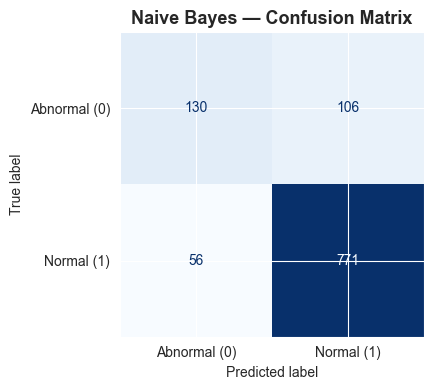

In [13]:
# Confusion matrix
#   [[TN, FP],
#    [FN, TP]]
cm_nb              = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])
TN_nb, FP_nb       = int(cm_nb[0, 0]), int(cm_nb[0, 1])
FN_nb, TP_nb       = int(cm_nb[1, 0]), int(cm_nb[1, 1])
TPR_nb             = TP_nb / (TP_nb + FN_nb)
TNR_nb             = TN_nb / (TN_nb + FP_nb)

print("Confusion Matrix — Naive Bayes")
print(f"  TP = {TP_nb:>4}   FP = {FP_nb:>4}")
print(f"  FN = {FN_nb:>4}   TN = {TN_nb:>4}")
print(f"  TPR (Sensitivity) = {TPR_nb:.4f}")
print(f"  TNR (Specificity) = {TNR_nb:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_nb, display_labels=['Abnormal (0)', 'Normal (1)']).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Naive Bayes — Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Question 3 : Decision Tree Classifier

Steps:
1. Same 50/50 split (same RANDOM_STATE → identical sets for fair comparison)
2. Train DecisionTreeClassifier (entropy criterion)  
3. Accuracy + confusion matrix


In [ ]:
# Train Decision Tree
dt_clf = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_accuracy:.4f}  ({dt_accuracy*100:.2f}%)")

Confusion Matrix — Decision Tree
  TP =  761   FP =   77
  FN =   66   TN =  159
  TPR (Sensitivity) = 0.9202
  TNR (Specificity) = 0.6737


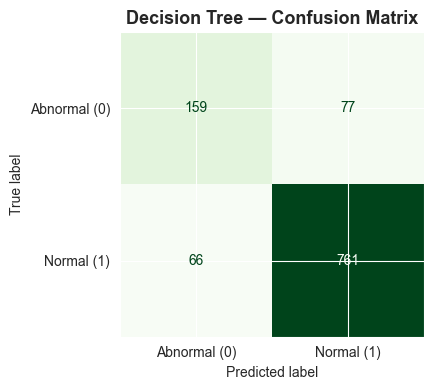

In [15]:
# Confusion matrix
cm_dt              = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])
TN_dt, FP_dt       = int(cm_dt[0, 0]), int(cm_dt[0, 1])
FN_dt, TP_dt       = int(cm_dt[1, 0]), int(cm_dt[1, 1])
TPR_dt             = TP_dt / (TP_dt + FN_dt)
TNR_dt             = TN_dt / (TN_dt + FP_dt)

print("Confusion Matrix — Decision Tree")
print(f"  TP = {TP_dt:>4}   FP = {FP_dt:>4}")
print(f"  FN = {FN_dt:>4}   TN = {TN_dt:>4}")
print(f"  TPR (Sensitivity) = {TPR_dt:.4f}")
print(f"  TNR (Specificity) = {TNR_dt:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_dt, display_labels=['Abnormal (0)', 'Normal (1)']).plot(
    ax=ax, colorbar=False, cmap='Greens')
ax.set_title('Decision Tree — Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Question 4 : Random Forest: N × d Hyperparameter Grid Search

Steps:
1. Grid: N ∈ {1…10}, d ∈ {1…5} — compute test error rate for every (N, d) pair  
2. Heatmap + line plot of error rates  
3. Best (N, d): accuracy + confusion matrix


In [ ]:
# Grid search over N (n_estimators) and d (max_depth)
N_VALUES   = list(range(1, 11))
D_VALUES   = list(range(1, 6))
error_grid = np.zeros((len(D_VALUES), len(N_VALUES)))

for i, d in enumerate(D_VALUES):
    for j, n in enumerate(N_VALUES):
        rf = RandomForestClassifier(
            n_estimators=n, max_depth=d,
            criterion='entropy', random_state=RANDOM_STATE
        )
        rf.fit(X_train, y_train)
        error_grid[i, j] = 1.0 - accuracy_score(y_test, rf.predict(X_test))

df_errors = pd.DataFrame(
    error_grid,
    index=[f'd={d}' for d in D_VALUES],
    columns=[f'N={n}' for n in N_VALUES]
)
print("Error Rate Grid (rows = max_depth d, cols = n_trees N):")
print(df_errors.round(4).to_string())

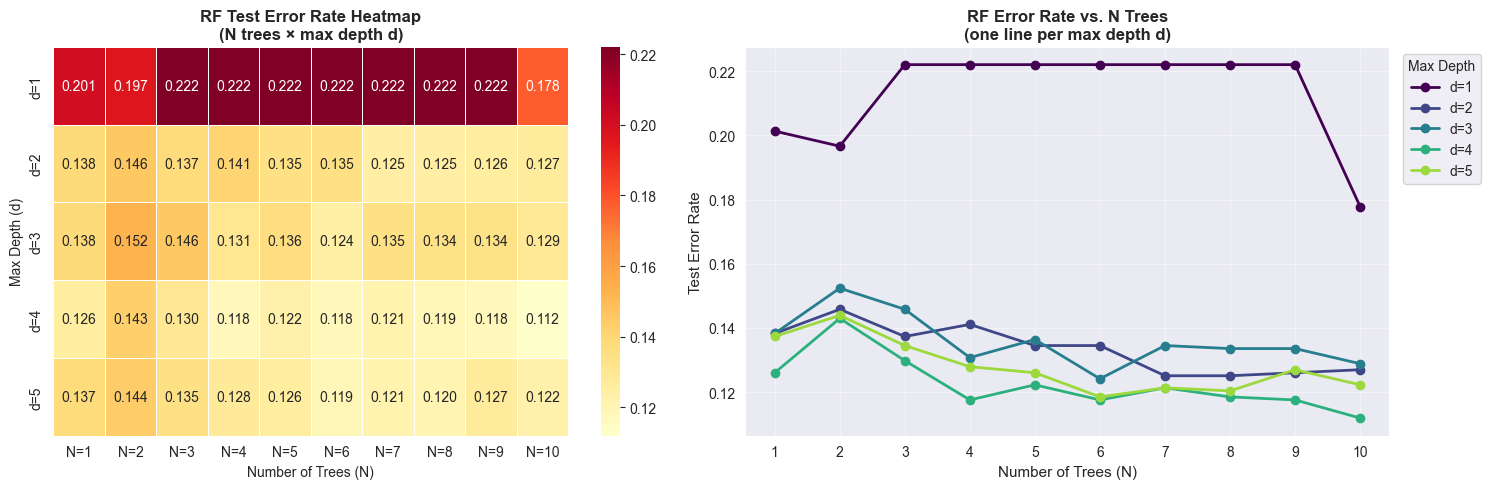

In [17]:
# Plot: Heatmap + Line Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(df_errors, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[0])
axes[0].set_title('RF Test Error Rate Heatmap\n(N trees × max depth d)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Trees (N)')
axes[0].set_ylabel('Max Depth (d)')

palette = plt.cm.viridis(np.linspace(0, 0.85, len(D_VALUES)))
for i, d in enumerate(D_VALUES):
    axes[1].plot(N_VALUES, error_grid[i], marker='o', label=f'd={d}',
                 color=palette[i], linewidth=2)
axes[1].set_xlabel('Number of Trees (N)', fontsize=11)
axes[1].set_ylabel('Test Error Rate', fontsize=11)
axes[1].set_title('RF Error Rate vs. N Trees\n(one line per max depth d)',
                  fontsize=12, fontweight='bold')
axes[1].set_xticks(N_VALUES)
axes[1].legend(title='Max Depth', bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [18]:
# Best (N, d)
min_idx = np.unravel_index(np.argmin(error_grid), error_grid.shape)
best_d   = D_VALUES[min_idx[0]]
best_N   = N_VALUES[min_idx[1]]
best_err = error_grid[min_idx]

print(f"Best combination  ->  N = {best_N}, d = {best_d}")
print(f"Best error rate   ->  {best_err:.4f}  (accuracy = {1-best_err:.4f},  {(1-best_err)*100:.2f}%)")

Best combination  ->  N = 10, d = 4
Best error rate   ->  0.1119  (accuracy = 0.8881,  88.81%)


Random Forest Accuracy (N=10, d=4): 0.8881  (88.81%)

Confusion Matrix — Random Forest (N=10, d=4)
  TP =  796   FP =   88
  FN =   31   TN =  148
  TPR (Sensitivity) = 0.9625
  TNR (Specificity) = 0.6271


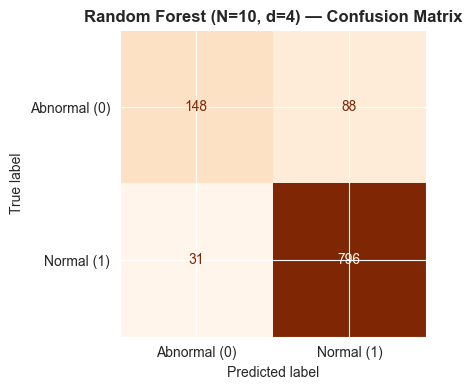

In [19]:
# Train final RF with best (N, d) and compute confusion matrix
rf_best = RandomForestClassifier(
    n_estimators=best_N, max_depth=best_d,
    criterion='entropy', random_state=RANDOM_STATE
)
rf_best.fit(X_train, y_train)
y_pred_rf   = rf_best.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy (N={best_N}, d={best_d}): {rf_accuracy:.4f}  ({rf_accuracy*100:.2f}%)")

cm_rf              = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
TN_rf, FP_rf       = int(cm_rf[0, 0]), int(cm_rf[0, 1])
FN_rf, TP_rf       = int(cm_rf[1, 0]), int(cm_rf[1, 1])
TPR_rf             = TP_rf / (TP_rf + FN_rf)
TNR_rf             = TN_rf / (TN_rf + FP_rf)

print(f"\nConfusion Matrix — Random Forest (N={best_N}, d={best_d})")
print(f"  TP = {TP_rf:>4}   FP = {FP_rf:>4}")
print(f"  FN = {FN_rf:>4}   TN = {TN_rf:>4}")
print(f"  TPR (Sensitivity) = {TPR_rf:.4f}")
print(f"  TNR (Specificity) = {TNR_rf:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_rf, display_labels=['Abnormal (0)', 'Normal (1)']).plot(
    ax=ax, colorbar=False, cmap='Oranges')
ax.set_title(f'Random Forest (N={best_N}, d={best_d}) — Confusion Matrix',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Question 5 : Summary Table & Discussion


In [ ]:
y_pred_nb = nb_clf.predict(X_test)
y_pred_dt = dt_clf.predict(X_test)
y_pred_rf = rf_best.predict(X_test)

nb_accuracy = accuracy_score(y_test, y_pred_nb)
dt_accuracy = accuracy_score(y_test, y_pred_dt)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

def get_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp = int(cm[0, 0]), int(cm[0, 1])
    fn, tp = int(cm[1, 0]), int(cm[1, 1])
    tpr = tp / (tp + fn)
    tnr = tn / (tn + fp)
    return tp, fp, tn, fn, tpr, tnr

TP_nb, FP_nb, TN_nb, FN_nb, TPR_nb, TNR_nb = get_metrics(y_test, y_pred_nb)
TP_dt, FP_dt, TN_dt, FN_dt, TPR_dt, TNR_dt = get_metrics(y_test, y_pred_dt)
TP_rf, FP_rf, TN_rf, FN_rf, TPR_rf, TNR_rf = get_metrics(y_test, y_pred_rf)

# Summary table
summary = pd.DataFrame({
    'Model':    ['Naive Bayes', 'Decision Tree',
                 f'Random Forest (N={best_N}, d={best_d})'],
    'TP':       [TP_nb,  TP_dt,  TP_rf],
    'FP':       [FP_nb,  FP_dt,  FP_rf],
    'TN':       [TN_nb,  TN_dt,  TN_rf],
    'FN':       [FN_nb,  FN_dt,  FN_rf],
    'Accuracy': [round(nb_accuracy,4), round(dt_accuracy,4), round(rf_accuracy,4)],
    'TPR':      [round(TPR_nb,4),      round(TPR_dt,4),      round(TPR_rf,4)],
    'TNR':      [round(TNR_nb,4),      round(TNR_dt,4),      round(TNR_rf,4)],
})
print("=" * 74)
print("  Model Comparison Summary")
print("=" * 74)
print(summary.to_string(index=False))
print("=" * 74)

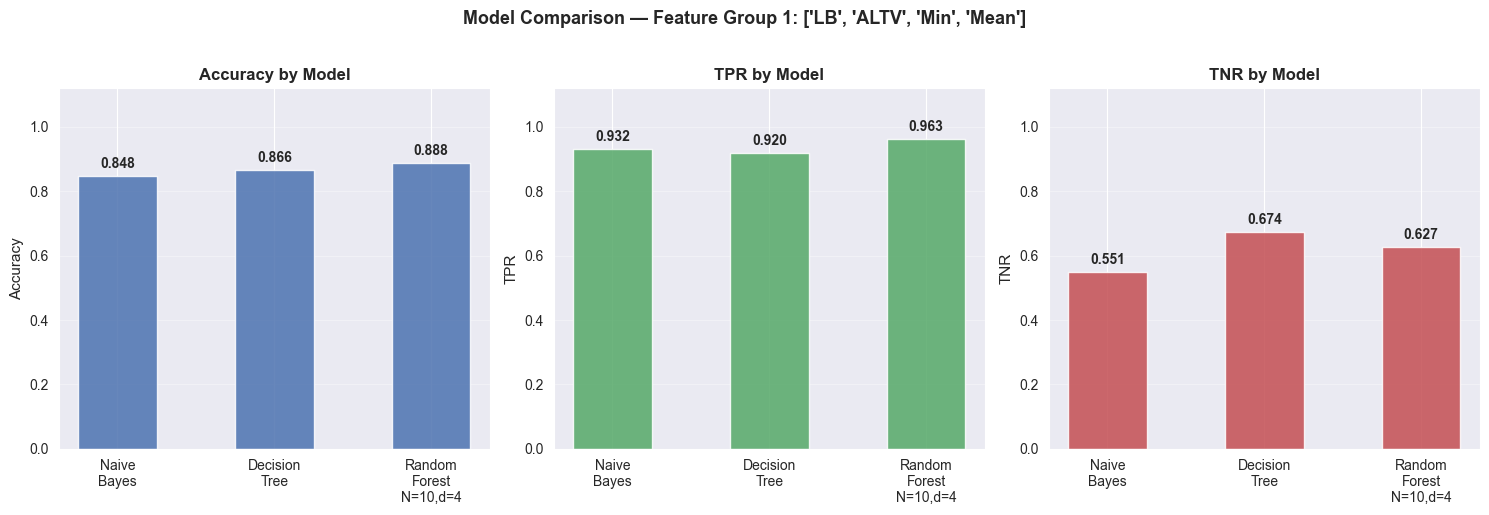

In [21]:
# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics    = ['Accuracy', 'TPR', 'TNR']
bar_colors = ['#4C72B0', '#55A868', '#C44E52']
labels     = ['Naive\nBayes', 'Decision\nTree',
               f'Random\nForest\nN={best_N},d={best_d}']

for ax, metric, color in zip(axes, metrics, bar_colors):
    vals = summary[metric].tolist()
    bars = ax.bar(labels, vals, color=color, alpha=0.85, edgecolor='white', width=0.5)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(f'{metric} by Model', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.35)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.015,
                f'{bar.get_height():.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle(f'Model Comparison — Feature Group {FEATURE_GROUP}: {FEATURES}',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Discussion

Naive Bayes:  
GaussianNB assumes all features are conditionally independent and Gaussian-distributed per class. CTG features such as LB (baseline FHR) and ALTV (abnormal long-term variability) are physiologically correlated, which directly violates the independence assumption and tends to depress NB accuracy on clinical datasets. Despite this, NB trains in microseconds and provides a strong, interpretable baseline.

Decision Tree:  
A fully-grown tree (no max_depth limit) can memorize the training set entirely but is prone to overfitting on noisy physiological signals. The entropy criterion was applied for consistency with Q4. If DT accuracy substantially outperforms NB, inspect whether the tree is memorizing noise in the 50 % training split rather than learning generalizable patterns.

Random Forest:  
RF aggregates N decorrelated trees, each grown on a bootstrap sample using a random feature subset. Bagging reduces variance without substantially increasing bias,  this is why RF almost always outperforms a single tree on tabular clinical data. The (N, d) grid search identifies the bias-variance sweet spot: shallow trees (d=1) underfit; deep trees with few estimators (N=1, d=5) overfit.

Key clinical framing:  
In fetal monitoring, False Negatives (missing a pathological fetus) are far costlier than False Positives. Production systems should be tuned primarily for high TPR (Sensitivity), accepting a modest accuracy trade-off if necessary.

Class-imbalance baseline:  
The dataset is ~77 % Normal. A trivial "always predict Normal" rule already scores ~77 % accuracy  always verify every model beats this before reporting results.
